<a href="https://colab.research.google.com/github/David-Moenga/Beginner-Data-Science-Projects/blob/main/capstone_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import zipfile

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
from google.colab import files
uploaded = files.upload()

Saving fmcg_raw_data 11.zip to fmcg_raw_data 11.zip


In [3]:
# Define the extraction directory
extract_path = '/content/fmcg_data'

# Create the directory
os.makedirs(extract_path, exist_ok=True)

# Get the uploaded ZIP filename
zip_filename = next(iter(uploaded))

# Extract all files
with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
for root, directories, filenames in os.walk(extract_path):
    for filename in filenames:
        print(os.path.join(root, filename))

/content/fmcg_data/data/climate_features.csv
/content/fmcg_data/data/Train.csv
/content/fmcg_data/data/data_dictionary.csv
/content/fmcg_data/data/Test.csv
/content/fmcg_data/data/fmcg_sales_3years_1M_rows.csv


In [5]:
# Define the location of our main dataset
file_path = (
    '/content/fmcg_data/data/'
    'fmcg_sales_3years_1M_rows.csv'
)

# Load the dataset
df = pd.read_csv(
    file_path,
    parse_dates=['date'],
    low_memory=False
)

print("FMCG dataset loaded successfully!")

FMCG dataset loaded successfully!


In [6]:
df.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,store_id,country,city,channel,latitude,longitude,sku_id,sku_name,category,subcategory,brand,units_sold,list_price,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,STORE0001,Germany,Berlin,Hypermarket,52.52586,13.39071,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,16,10.49,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,STORE0001,Germany,Berlin,Hypermarket,52.52586,13.39071,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,12,10.49,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,STORE0001,Germany,Berlin,Hypermarket,52.52586,13.39071,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,38,10.49,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,STORE0001,Germany,Berlin,Hypermarket,52.52586,13.39071,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,8,10.49,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,STORE0001,Germany,Berlin,Hypermarket,52.52586,13.39071,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,17,10.49,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [7]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1100000
Number of columns: 33


In [8]:
#examining columns names
df.columns.tolist()

['date',
 'year',
 'month',
 'day',
 'weekofyear',
 'weekday',
 'is_weekend',
 'is_holiday',
 'temperature',
 'rain_mm',
 'store_id',
 'country',
 'city',
 'channel',
 'latitude',
 'longitude',
 'sku_id',
 'sku_name',
 'category',
 'subcategory',
 'brand',
 'units_sold',
 'list_price',
 'discount_pct',
 'promo_flag',
 'gross_sales',
 'net_sales',
 'stock_on_hand',
 'stock_out_flag',
 'lead_time_days',
 'supplier_id',
 'purchase_cost',
 'margin_pct']

In [9]:
#understanding the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100000 entries, 0 to 1099999
Data columns (total 33 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   date            1100000 non-null  datetime64[ns]
 1   year            1100000 non-null  int64         
 2   month           1100000 non-null  int64         
 3   day             1100000 non-null  int64         
 4   weekofyear      1100000 non-null  int64         
 5   weekday         1100000 non-null  int64         
 6   is_weekend      1100000 non-null  int64         
 7   is_holiday      1100000 non-null  int64         
 8   temperature     1100000 non-null  float64       
 9   rain_mm         1100000 non-null  float64       
 10  store_id        1100000 non-null  object        
 11  country         1100000 non-null  object        
 12  city            1100000 non-null  object        
 13  channel         1100000 non-null  object        
 14  latitude        11

Checking for missing values


In [10]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Create a summary table
missing_summary = pd.DataFrame({
    'Column': missing_values.index,
    'Missing_Values': missing_values.values,
    'Missing_Percentage': (
        missing_values.values / len(df) * 100
    ).round(2)
})

# Sort by missing values
missing_summary = missing_summary.sort_values(
    by='Missing_Values',
    ascending=False
)

missing_summary

,Column,Missing_Values,Missing_Percentage
0,date,0,0.0
1,year,0,0.0
2,month,0,0.0
3,day,0,0.0
4,weekofyear,0,0.0
5,weekday,0,0.0
6,is_weekend,0,0.0
7,is_holiday,0,0.0
8,temperature,0,0.0
9,rain_mm,0,0.0


Checking duplicate records

In [11]:
# Counting exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 0


Checking numerical statistics

In [12]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,1100000,2022-07-01 20:47:14.181818368,2021-01-01 00:00:00,2021-10-01 00:00:00,2022-07-02 00:00:00,2023-04-02 00:00:00,2023-12-31 00:00:00,NaN
year,1100000.0,2021.999668,2021.0,2021.0,2022.0,2023.0,2023.0,0.81647
month,1100000.0,6.525613,1.0,4.0,7.0,10.0,12.0,3.44776
day,1100000.0,15.720444,1.0,8.0,16.0,23.0,31.0,8.796262
weekofyear,1100000.0,26.570811,1.0,14.0,27.0,40.0,53.0,15.051255
weekday,1100000.0,3.005479,0.0,1.0,3.0,5.0,6.0,2.000451
is_weekend,1100000.0,0.286758,0.0,0.0,0.0,1.0,1.0,0.452248
is_holiday,1100000.0,0.013698,0.0,0.0,0.0,0.0,1.0,0.116235
temperature,1100000.0,12.815005,1.8,10.61,12.84,15.0,22.83,3.371587
rain_mm,1100000.0,2.904106,0.0,1.22,2.57,4.15,11.58,2.098997


Examining categorical columns

In [13]:
categorical_columns = df.select_dtypes(
    include='object'
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts().head(10))


store_id
Unique values: 13
store_id
STORE0001    87600
STORE0002    87600
STORE0003    87600
STORE0004    87600
STORE0005    87600
STORE0006    87600
STORE0007    87600
STORE0008    87600
STORE0009    87600
STORE0010    87600
Name: count, dtype: int64

country
Unique values: 7
country
Italy          350400
Spain          262800
Germany        175200
Poland          87600
France          87600
Austria         87600
Netherlands     48800
Name: count, dtype: int64

city
Unique values: 9
city
Berlin       175200
Rome         175200
Milan        175200
Barcelona    175200
Warsaw        87600
Paris         87600
Vienna        87600
Madrid        87600
Amsterdam     48800
Name: count, dtype: int64

channel
Unique values: 4
channel
Hypermarket    525600
Supermarket    262800
E-commerce     262800
Convenience     48800
Name: count, dtype: int64

sku_id
Unique values: 102
sku_id
SKU0020    14235
SKU0001    14235
SKU0096    14235
SKU0039    14235
SKU0015    13140
SKU0006    13140
SKU0056    1314

In [14]:
print("First date:", df['date'].min())
print("Last date:", df['date'].max())

print(
    "Unique dates:",
    df['date'].nunique()
)

First date: 2021-01-01 00:00:00
Last date: 2023-12-31 00:00:00
Unique dates: 1095


In [15]:
# Generate a complete daily date range
complete_dates = pd.date_range(
    start=df['date'].min(),
    end=df['date'].max(),
    freq='D'
)

# Identify dates not represented anywhere in the dataset
missing_dates = complete_dates.difference(
    pd.DatetimeIndex(df['date'].unique())
)

print("Expected calendar days:", len(complete_dates))
print("Observed calendar days:", df['date'].nunique())
print("Missing calendar dates:", len(missing_dates))

Expected calendar days: 1095
Observed calendar days: 1095
Missing calendar dates: 0


Checking possible invalid values

In [16]:
print("Negative units sold:",
      (df['units_sold'] < 0).sum())

print("Zero units sold:",
      (df['units_sold'] == 0).sum())

print("Negative prices:",
      (df['list_price'] < 0).sum())

print("Zero prices:",
      (df['list_price'] == 0).sum())

print("Invalid discount percentages:",
      (~df['discount_pct'].between(0, 1)).sum())

print("Invalid promotion flags:",
      (~df['promo_flag'].isin([0, 1])).sum())

print("Negative stock:",
      (df['stock_on_hand'] < 0).sum())

Negative units sold: 0
Zero units sold: 3092
Negative prices: 0
Zero prices: 0
Invalid discount percentages: 0
Invalid promotion flags: 0
Negative stock: 0


In [17]:
# Define the potential record identifier
record_key = [
    'date',
    'store_id',
    'sku_id',
    'channel'
]

# Count repeated combinations
repeated_combinations = df.duplicated(
    subset=record_key
).sum()

print(
    "Repeated date-store-product-channel combinations:",
    repeated_combinations
)

Repeated date-store-product-channel combinations: 0


Checking Data Quality Summary

In [18]:
quality_report = pd.DataFrame({
    'Check': [
        'Total records',
        'Total columns',
        'Missing values',
        'Exact duplicate rows',
        'Negative sales quantities',
        'Zero sales quantities',
        'Negative prices',
        'Invalid discount percentages',
        'Invalid promotion flags',
        'Negative stock quantities'
    ],
    'Result': [
        len(df),
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        (df['units_sold'] < 0).sum(),
        (df['units_sold'] == 0).sum(),
        (df['list_price'] < 0).sum(),
        (~df['discount_pct'].between(0, 1)).sum(),
        (~df['promo_flag'].isin([0, 1])).sum(),
        (df['stock_on_hand'] < 0).sum()
    ]
})

quality_report

,Check,Result
0,Total records,1100000
1,Total columns,33
2,Missing values,0
3,Exact duplicate rows,0
4,Negative sales quantities,0
5,Zero sales quantities,3092
6,Negative prices,0
7,Invalid discount percentages,0
8,Invalid promotion flags,0
9,Negative stock quantities,0


In [19]:
record_key = [
    'date',
    'store_id',
    'sku_id',
    'channel'
]

duplicate_combinations = df.duplicated(
    subset=record_key
).sum()

print("Repeated combinations:", duplicate_combinations)

Repeated combinations: 0


Validating sales calculations

In [20]:
# Calculate expected gross sales
expected_gross = df['units_sold'] * df['list_price']

# Calculate expected net sales
expected_net = (
    df['gross_sales'] * (1 - df['discount_pct'])
)

# Compare actual and expected values
gross_mismatches = (
    ~np.isclose(df['gross_sales'], expected_gross, atol=0.02)
).sum()

net_mismatches = (
    ~np.isclose(df['net_sales'], expected_net, atol=0.03)
).sum()

print("Gross sales mismatches:", gross_mismatches)
print("Net sales mismatches:", net_mismatches)

Gross sales mismatches: 0
Net sales mismatches: 0


In [21]:
pd.crosstab(
    df['promo_flag'],
    df['discount_pct'] > 0,
    rownames=['Promotion Flag'],
    colnames=['Has Discount'],
    margins=True
)

Has Discount,False,True,All
Promotion Flag,,,
0,1011743,0,1011743
1,0,88257,88257
All,1011743,88257,1100000


In [22]:
stockout_analysis = pd.crosstab(
    df['stock_out_flag'],
    df['stock_on_hand'] == 0,
    rownames=['Stockout Flag'],
    colnames=['Stock on Hand is Zero']
)

stockout_analysis

Stock on Hand is Zero,False,True
Stockout Flag,,
0,1066782,104
1,33110,4


SQL extraction and aggregation

In [23]:
import sqlite3

# Create an SQLite database
conn = sqlite3.connect('/content/fmcg_analysis.db')

# Load the DataFrame into a SQL table
df.to_sql(
    'fmcg_sales',
    conn,
    if_exists='replace',
    index=False
)

print("Dataset successfully loaded into SQLite.")

Dataset successfully loaded into SQLite.


In [24]:
query = """
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT store_id) AS total_stores,
    COUNT(DISTINCT sku_id) AS total_products,
    COUNT(DISTINCT country) AS total_countries,
    SUM(units_sold) AS total_units_sold,
    ROUND(SUM(gross_sales), 2) AS total_gross_sales,
    ROUND(SUM(net_sales), 2) AS total_net_sales
FROM fmcg_sales;
"""

sql_summary = pd.read_sql_query(query, conn)

sql_summary

,total_records,total_stores,total_products,total_countries,total_units_sold,total_gross_sales,total_net_sales
0,1100000,13,102,7,65115982,4.847487e+08,4.729465e+08


In [25]:
sql_summary.style.format({
    'total_records': '{:,.0f}',
    'total_stores': '{:,.0f}',
    'total_products': '{:,.0f}',
    'total_countries': '{:,.0f}',
    'total_units_sold': '{:,.0f}',
    'total_gross_sales': '{:,.2f}',
    'total_net_sales': '{:,.2f}'
})

,total_records,total_stores,total_products,total_countries,total_units_sold,total_gross_sales,total_net_sales
0,"1,100,000",13,102,7,"65,115,982","484,748,674.02","472,946,452.83"


In [26]:
sql_summary.style.format({
    'total_records': '{:,.0f}',
    'total_stores': '{:,.0f}',
    'total_products': '{:,.0f}',
    'total_countries': '{:,.0f}',
    'total_units_sold': '{:,.0f}',
    'total_gross_sales': '{:,.2f}',
    'total_net_sales': '{:,.2f}'
})

,total_records,total_stores,total_products,total_countries,total_units_sold,total_gross_sales,total_net_sales
0,"1,100,000",13,102,7,"65,115,982","484,748,674.02","472,946,452.83"


Which countries generate the most revenue?

In [27]:
country_query = """
SELECT
    country,
    COUNT(*) AS total_records,
    SUM(units_sold) AS total_units_sold,
    ROUND(SUM(gross_sales), 2) AS gross_revenue,
    ROUND(SUM(net_sales), 2) AS net_revenue,
    ROUND(AVG(discount_pct) * 100, 2) AS average_discount_pct
FROM fmcg_sales
GROUP BY country
ORDER BY net_revenue DESC;
"""

country_analysis = pd.read_sql_query(country_query, conn)

country_analysis

,country,total_records,total_units_sold,gross_revenue,net_revenue,average_discount_pct
0,Italy,350400,19361774,1.406284e+08,1.371931e+08,1.48
1,Spain,262800,14668017,1.092797e+08,1.067048e+08,1.46
2,Germany,175200,11738571,9.076660e+07,8.852556e+07,1.52
3,Austria,87600,5742174,4.401877e+07,4.302003e+07,1.40
4,France,87600,6014974,4.363114e+07,4.260161e+07,1.54
5,Poland,87600,5860180,4.353548e+07,4.238526e+07,1.59
6,Netherlands,48800,1730292,1.288850e+07,1.251615e+07,1.67


In [28]:
country_analysis['revenue_contribution_pct'] = (
    country_analysis['net_revenue']
    / country_analysis['net_revenue'].sum()
) * 100

country_analysis['revenue_per_record'] = (
    country_analysis['net_revenue']
    / country_analysis['total_records']
)

country_analysis['revenue_per_unit'] = (
    country_analysis['net_revenue']
    / country_analysis['total_units_sold']
)

country_analysis.round(2)

,country,total_records,total_units_sold,gross_revenue,net_revenue,average_discount_pct,revenue_contribution_pct,revenue_per_record,revenue_per_unit
0,Italy,350400,19361774,1.406284e+08,1.371931e+08,1.48,29.01,391.53,7.09
1,Spain,262800,14668017,1.092797e+08,1.067048e+08,1.46,22.56,406.03,7.27
2,Germany,175200,11738571,9.076660e+07,8.852556e+07,1.52,18.72,505.28,7.54
3,Austria,87600,5742174,4.401877e+07,4.302003e+07,1.40,9.10,491.10,7.49
4,France,87600,6014974,4.363114e+07,4.260161e+07,1.54,9.01,486.32,7.08
5,Poland,87600,5860180,4.353548e+07,4.238526e+07,1.59,8.96,483.85,7.23
6,Netherlands,48800,1730292,1.288850e+07,1.251615e+07,1.67,2.65,256.48,7.23


Product Category Analysis

In [29]:
category_query = """
SELECT
    category,
    COUNT(*) AS total_records,
    COUNT(DISTINCT sku_id) AS unique_products,
    SUM(units_sold) AS total_units_sold,
    ROUND(SUM(gross_sales), 2) AS gross_revenue,
    ROUND(SUM(net_sales), 2) AS net_revenue,
    ROUND(AVG(discount_pct) * 100, 2) AS average_discount_pct
FROM fmcg_sales
GROUP BY category
ORDER BY net_revenue DESC;
"""

category_analysis = pd.read_sql_query(
    category_query,
    conn
)

category_analysis

,category,total_records,unique_products,total_units_sold,gross_revenue,net_revenue,average_discount_pct
0,Snacks,261705,24,16724604,1.344444e+08,1.301432e+08,1.83
1,Beverages,266085,24,18090386,1.072778e+08,1.041037e+08,1.72
2,Personal Care,199290,18,10799580,9.117028e+07,8.955029e+07,1.43
3,Dairy,196005,18,10224202,8.465573e+07,8.382053e+07,1.12
4,Home Care,176915,18,9277210,6.720049e+07,6.532865e+07,1.17


category revenue contribution calculation

In [30]:
category_analysis['revenue_contribution_pct'] = (
    category_analysis['net_revenue']
    / category_analysis['net_revenue'].sum()
) * 100

category_analysis['revenue_per_product'] = (
    category_analysis['net_revenue']
    / category_analysis['unique_products']
)

category_analysis['units_per_record'] = (
    category_analysis['total_units_sold']
    / category_analysis['total_records']
)

category_analysis.round(2)

,category,total_records,unique_products,total_units_sold,gross_revenue,net_revenue,average_discount_pct,revenue_contribution_pct,revenue_per_product,units_per_record
0,Snacks,261705,24,16724604,1.344444e+08,1.301432e+08,1.83,27.52,5422635.27,63.91
1,Beverages,266085,24,18090386,1.072778e+08,1.041037e+08,1.72,22.01,4337655.49,67.99
2,Personal Care,199290,18,10799580,9.117028e+07,8.955029e+07,1.43,18.93,4975016.09,54.19
3,Dairy,196005,18,10224202,8.465573e+07,8.382053e+07,1.12,17.72,4656696.17,52.16
4,Home Care,176915,18,9277210,6.720049e+07,6.532865e+07,1.17,13.81,3629369.67,52.44


Sales Channel Performance Analysis

In [31]:
channel_query = """
SELECT
    channel,
    COUNT(*) AS total_records,
    COUNT(DISTINCT store_id) AS unique_stores,
    SUM(units_sold) AS total_units_sold,
    ROUND(SUM(gross_sales), 2) AS gross_revenue,
    ROUND(SUM(net_sales), 2) AS net_revenue,
    ROUND(AVG(discount_pct) * 100, 2) AS average_discount_pct
FROM fmcg_sales
GROUP BY channel
ORDER BY net_revenue DESC;
"""

channel_analysis = pd.read_sql_query(
    channel_query,
    conn
)

channel_analysis

,channel,total_records,unique_stores,total_units_sold,gross_revenue,net_revenue,average_discount_pct
0,Hypermarket,525600,6,35341421,2.651321e+08,2.587381e+08,1.49
1,E-commerce,262800,3,15647980,1.155181e+08,1.127345e+08,1.51
2,Supermarket,262800,3,12396289,9.121003e+07,8.895766e+07,1.46
3,Convenience,48800,1,1730292,1.288850e+07,1.251615e+07,1.67


In [32]:
channel_analysis['revenue_contribution_pct'] = (
    channel_analysis['net_revenue']
    / channel_analysis['net_revenue'].sum()
) * 100

channel_analysis['revenue_per_record'] = (
    channel_analysis['net_revenue']
    / channel_analysis['total_records']
)

channel_analysis['units_per_record'] = (
    channel_analysis['total_units_sold']
    / channel_analysis['total_records']
)

channel_analysis.round(2)

,channel,total_records,unique_stores,total_units_sold,gross_revenue,net_revenue,average_discount_pct,revenue_contribution_pct,revenue_per_record,units_per_record
0,Hypermarket,525600,6,35341421,2.651321e+08,2.587381e+08,1.49,54.71,492.27,67.24
1,E-commerce,262800,3,15647980,1.155181e+08,1.127345e+08,1.51,23.84,428.97,59.54
2,Supermarket,262800,3,12396289,9.121003e+07,8.895766e+07,1.46,18.81,338.50,47.17
3,Convenience,48800,1,1730292,1.288850e+07,1.251615e+07,1.67,2.65,256.48,35.46


Aggregating daily sales

In [33]:
daily_sales = df.groupby('date').agg(
    total_units_sold=('units_sold', 'sum'),
    total_net_revenue=('net_sales', 'sum'),
    total_gross_revenue=('gross_sales', 'sum')
).reset_index()

daily_sales.head()

,date,total_units_sold,total_net_revenue,total_gross_revenue
0,2021-01-01,53924,395308.15,404656.55
1,2021-01-02,68546,482497.08,497548.92
2,2021-01-03,68066,481362.59,492731.30
3,2021-01-04,55802,396538.69,409114.87
4,2021-01-05,53234,393292.28,400858.82


Visualising daily sales

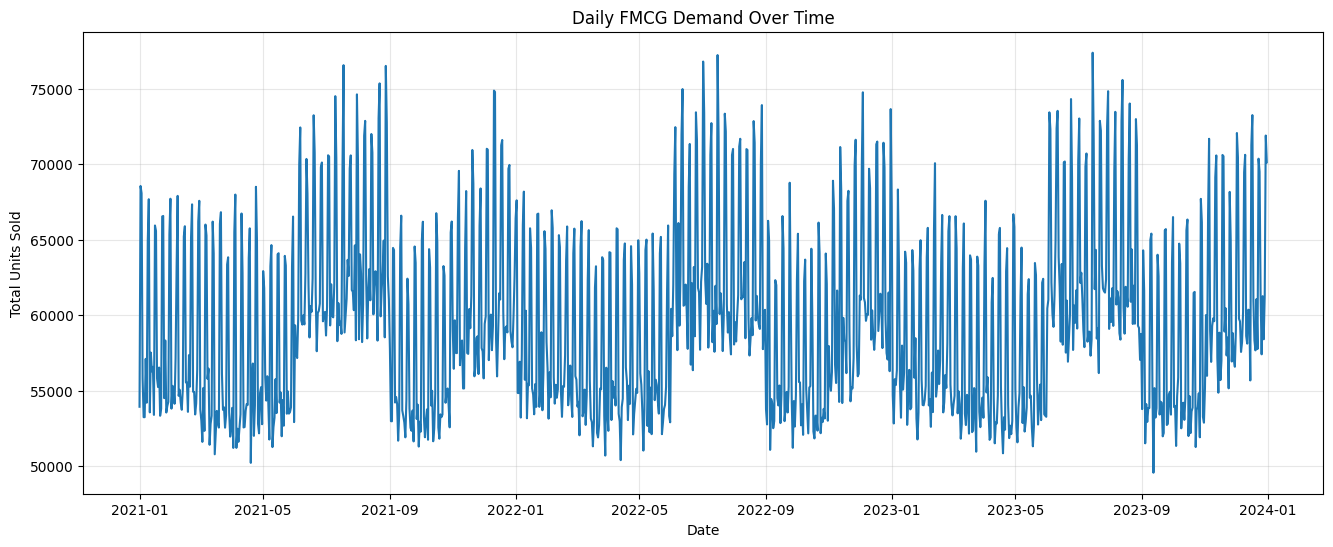

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales['date'],
    daily_sales['total_units_sold']
)

plt.title('Daily FMCG Demand Over Time')
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.grid(alpha=0.3)

plt.show()

monthly demand analysis

In [35]:
monthly_sales = df.groupby(
    df['date'].dt.to_period('M')
).agg(
    total_units_sold=('units_sold', 'sum'),
    total_net_revenue=('net_sales', 'sum')
).reset_index()

monthly_sales['date'] = monthly_sales['date'].dt.to_timestamp()

monthly_sales.head()

,date,total_units_sold,total_net_revenue
0,2021-01-01,1820815,13146751.83
1,2021-02-01,1627648,11837396.87
2,2021-03-01,1746833,12740242.56
3,2021-04-01,1695518,12385409.98
4,2021-05-01,1766192,12915862.11


Visualization of monthly demand analysis

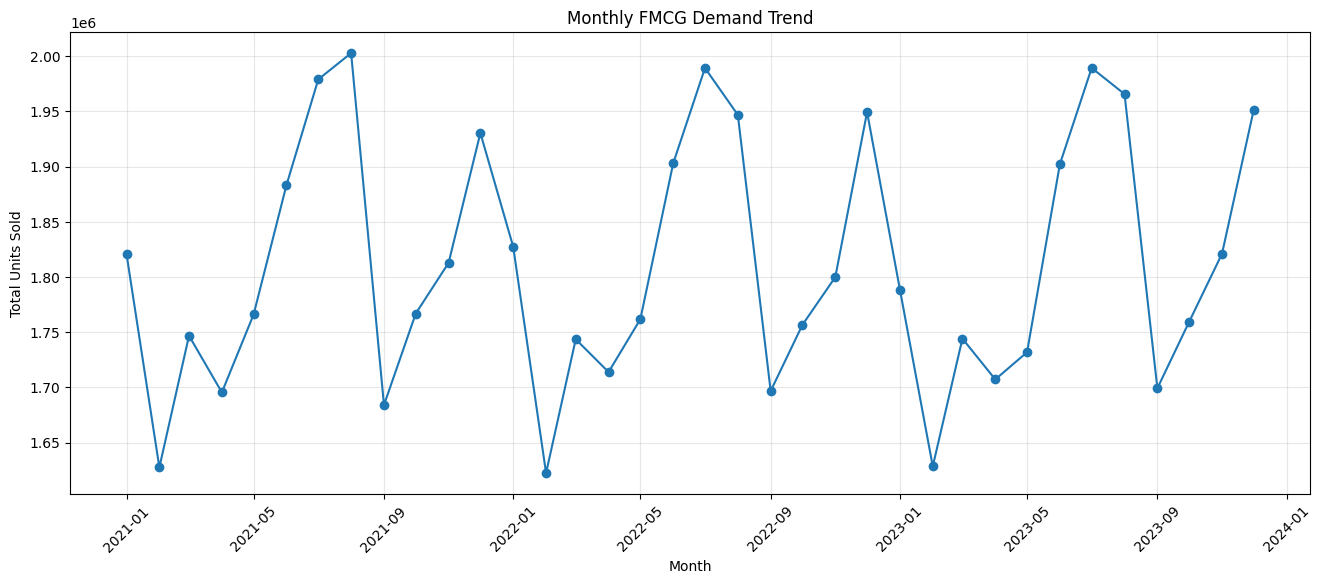

In [36]:
plt.figure(figsize=(16, 6))

plt.plot(
    monthly_sales['date'],
    monthly_sales['total_units_sold'],
    marker='o'
)

plt.title('Monthly FMCG Demand Trend')
plt.xlabel('Month')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

weekly demand pattern analysis

In [37]:
# Calculate average daily demand by weekday
weekday_sales = df.groupby('weekday').agg(
    average_units_sold=('units_sold', 'sum'),
    total_records=('units_sold', 'count')
).reset_index()

# Calculate average units sold per record
weekday_sales['average_units_per_record'] = (
    weekday_sales['average_units_sold']
    / weekday_sales['total_records']
)

# Map weekday numbers to names
weekday_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

weekday_sales['day_name'] = weekday_sales['weekday'].map(weekday_names)

weekday_sales

,weekday,average_units_sold,total_records,average_units_per_record,day_name
0,0,8769022,156713,55.955932,Monday
1,1,8790786,156712,56.095168,Tuesday
2,2,8780779,156712,56.031312,Wednesday
3,3,8797739,156712,56.139536,Thursday
4,4,8813207,157717,55.879880,Friday
5,5,10573143,157717,67.038702,Saturday
6,6,10591306,157717,67.153864,Sunday


Visualization of the weekly demand pattern analysis

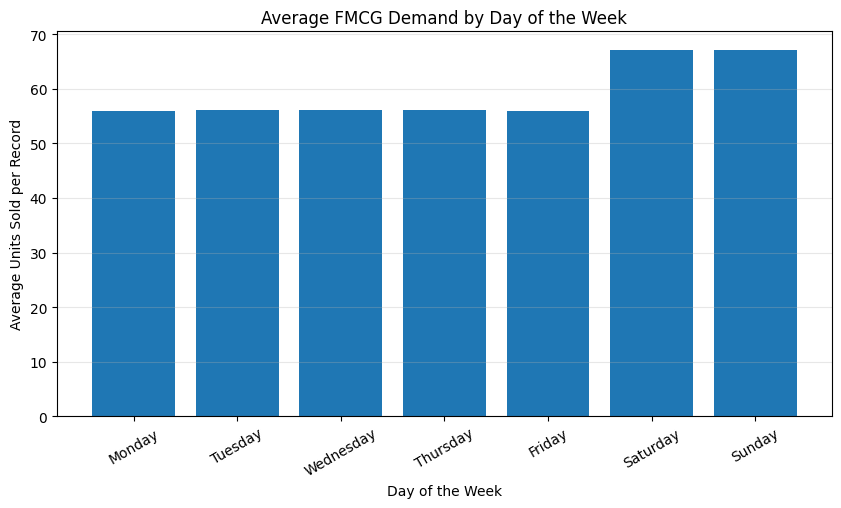

In [38]:
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_sales['day_name'],
    weekday_sales['average_units_per_record']
)

plt.title('Average FMCG Demand by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Units Sold per Record')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)

plt.show()

Investigating monthly seasonality

In [39]:
# Extract month from date
df['month_name'] = df['date'].dt.month

# Calculate average monthly demand across all three years
seasonal_sales = df.groupby('month_name').agg(
    total_units_sold=('units_sold', 'sum'),
    total_records=('units_sold', 'count')
).reset_index()

seasonal_sales['average_units_per_record'] = (
    seasonal_sales['total_units_sold']
    / seasonal_sales['total_records']
)

month_names = {
    1: 'January',
    2: 'February',
    3: 'March',
    4: 'April',
    5: 'May',
    6: 'June',
    7: 'July',
    8: 'August',
    9: 'September',
    10: 'October',
    11: 'November',
    12: 'December'
}

seasonal_sales['month_name'] = seasonal_sales['month_name'].map(month_names)

seasonal_sales

,month_name,total_units_sold,total_records,average_units_per_record
0,January,5436700,93434,58.187598
1,February,4878714,84392,57.810148
2,March,5234700,93434,56.025644
3,April,5116740,90420,56.588587
4,May,5259944,93434,56.295824
5,June,5688462,90420,62.911546
6,July,5957331,93434,63.759777
7,August,5915104,93434,63.307832
8,September,5080149,90402,56.195095
9,October,5283103,93403,56.562455


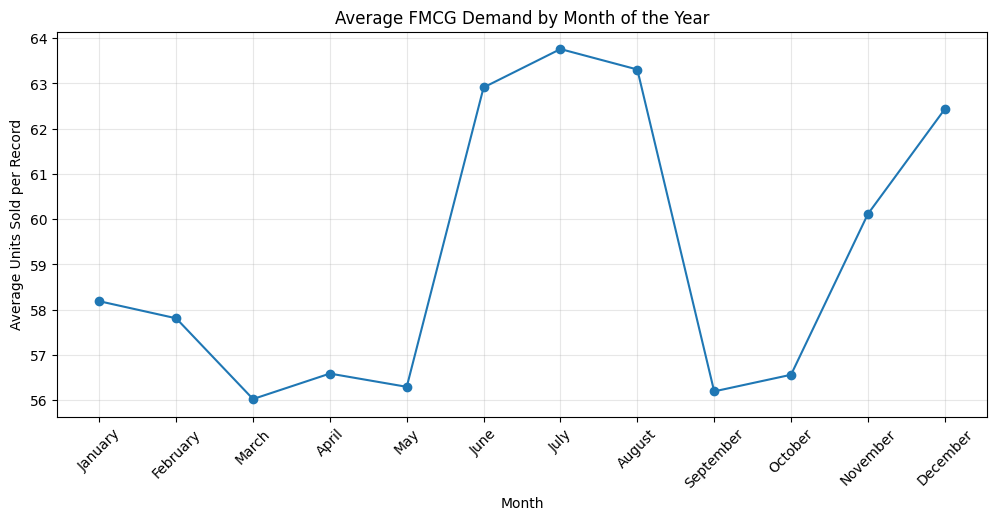

In [40]:
plt.figure(figsize=(12, 5))

plt.plot(
    seasonal_sales['month_name'],
    seasonal_sales['average_units_per_record'],
    marker='o'
)

plt.title('Average FMCG Demand by Month of the Year')
plt.xlabel('Month')
plt.ylabel('Average Units Sold per Record')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

In [41]:
daily_sales['weekday'] = daily_sales['date'].dt.dayofweek

daily_sales['day_type'] = np.where(
    daily_sales['weekday'].isin([5, 6]),
    'Weekend',
    'Weekday'
)

weekend_comparison = daily_sales.groupby('day_type').agg(
    average_daily_demand=('total_units_sold', 'mean'),
    total_demand=('total_units_sold', 'sum'),
    number_of_days=('date', 'count')
).reset_index()

weekend_comparison

,day_type,average_daily_demand,total_demand,number_of_days
0,Weekday,56275.970551,43951533,781
1,Weekend,67402.703822,21164449,314


ABC/XYZ practical implementations

In [42]:
# Check the number of unique products
print("Unique SKUs:", df['sku_id'].nunique())

# Inspect product information
product_info = df[
    ['sku_id', 'sku_name', 'category', 'purchase_cost']
].drop_duplicates()

print("Unique product information records:", len(product_info))

product_info.head(10)

Unique SKUs: 102
Unique product information records: 23688


,sku_id,sku_name,category,purchase_cost
0,SKU0086,BrandB Shampoo,Personal Care,7.53
1,SKU0086,BrandB Shampoo,Personal Care,5.19
2,SKU0086,BrandB Shampoo,Personal Care,5.59
3,SKU0086,BrandB Shampoo,Personal Care,7.81
4,SKU0086,BrandB Shampoo,Personal Care,7.62
5,SKU0086,BrandB Shampoo,Personal Care,5.35
6,SKU0086,BrandB Shampoo,Personal Care,7.19
7,SKU0086,BrandB Shampoo,Personal Care,6.78
8,SKU0086,BrandB Shampoo,Personal Care,5.38
9,SKU0086,BrandB Shampoo,Personal Care,6.99


In [43]:
cost_variation = df.groupby('sku_id').agg(
    unique_names=('sku_name', 'nunique'),
    unique_categories=('category', 'nunique'),
    min_purchase_cost=('purchase_cost', 'min'),
    max_purchase_cost=('purchase_cost', 'max'),
    average_purchase_cost=('purchase_cost', 'mean')
).reset_index()

cost_variation.head(10)

,sku_id,unique_names,unique_categories,min_purchase_cost,max_purchase_cost,average_purchase_cost
0,SKU0001,1,1,2.81,4.68,3.747846
1,SKU0002,1,1,5.06,8.44,6.765442
2,SKU0003,1,1,1.43,2.38,1.910785
3,SKU0004,1,1,0.81,1.36,1.088046
4,SKU0005,1,1,4.24,7.06,5.651088
5,SKU0006,1,1,0.58,0.97,0.774153
6,SKU0007,1,1,5.69,9.49,7.588266
7,SKU0008,1,1,1.60,2.66,2.127312
8,SKU0009,1,1,2.37,3.94,3.154865
9,SKU0010,1,1,3.17,5.29,4.238253


In [44]:
# Calculate inventory consumption value for every sales record
df['consumption_value'] = (
    df['units_sold'] * df['purchase_cost']
)

# Aggregate financial and sales information by product
product_abc = df.groupby(
    ['sku_id', 'sku_name', 'category']
).agg(
    total_units_sold=('units_sold', 'sum'),
    total_consumption_value=('consumption_value', 'sum')
).reset_index()

# Sort products from highest to lowest consumption value
product_abc = product_abc.sort_values(
    'total_consumption_value',
    ascending=False
).reset_index(drop=True)

product_abc.head(10)

,sku_id,sku_name,category,total_units_sold,total_consumption_value
0,SKU0027,BrandC Chips,Snacks,1200897,10202984.25
1,SKU0018,BrandF Water,Beverages,1173032,10201828.51
2,SKU0099,BrandC Toothpaste,Personal Care,1242389,8320295.30
3,SKU0026,BrandB Chips,Snacks,893989,7836533.94
4,SKU0092,BrandB Soap,Personal Care,895842,7497644.85
5,SKU0100,BrandD Toothpaste,Personal Care,920354,7413030.85
6,SKU0064,BrandD Cheese,Dairy,990120,7362677.09
7,SKU0061,BrandA Cheese,Dairy,972948,7167786.88
8,SKU0028,BrandD Chips,Snacks,1253907,7047743.56
9,SKU0041,BrandE Biscuits,Snacks,888200,6966794.21


In [45]:
product_info = df[
    ['sku_id', 'sku_name', 'category']
].drop_duplicates()

print("Unique product records:", len(product_info))

product_info.head(10)

Unique product records: 102


,sku_id,sku_name,category
0,SKU0086,BrandB Shampoo,Personal Care
1095,SKU0016,BrandD Water,Beverages
2190,SKU0049,BrandA Yogurt,Dairy
3285,SKU0036,BrandF Chocolate,Snacks
4380,SKU0006,BrandF Soda,Beverages
5475,SKU0067,BrandA Detergent,Home Care
6570,SKU0063,BrandC Cheese,Dairy
7665,SKU0008,BrandB Juice,Beverages
8760,SKU0093,BrandC Soap,Personal Care
9855,SKU0018,BrandF Water,Beverages


In [46]:
# Calculate total inventory consumption value
total_consumption = product_abc[
    'total_consumption_value'
].sum()

# Calculate each product's percentage contribution
product_abc['contribution_pct'] = (
    product_abc['total_consumption_value']
    / total_consumption
) * 100

product_abc.head(10)

,sku_id,sku_name,category,total_units_sold,total_consumption_value,contribution_pct
0,SKU0027,BrandC Chips,Snacks,1200897,10202984.25,3.509346
1,SKU0018,BrandF Water,Beverages,1173032,10201828.51,3.508948
2,SKU0099,BrandC Toothpaste,Personal Care,1242389,8320295.30,2.861790
3,SKU0026,BrandB Chips,Snacks,893989,7836533.94,2.695398
4,SKU0092,BrandB Soap,Personal Care,895842,7497644.85,2.578837
5,SKU0100,BrandD Toothpaste,Personal Care,920354,7413030.85,2.549733
6,SKU0064,BrandD Cheese,Dairy,990120,7362677.09,2.532414
7,SKU0061,BrandA Cheese,Dairy,972948,7167786.88,2.465381
8,SKU0028,BrandD Chips,Snacks,1253907,7047743.56,2.424092
9,SKU0041,BrandE Biscuits,Snacks,888200,6966794.21,2.396249


In [47]:
product_abc['cumulative_pct'] = (
    product_abc['contribution_pct'].cumsum()
)

product_abc.head(15)

,sku_id,sku_name,category,total_units_sold,total_consumption_value,contribution_pct,cumulative_pct
0,SKU0027,BrandC Chips,Snacks,1200897,10202984.25,3.509346,3.509346
1,SKU0018,BrandF Water,Beverages,1173032,10201828.51,3.508948,7.018294
2,SKU0099,BrandC Toothpaste,Personal Care,1242389,8320295.30,2.861790,9.880084
3,SKU0026,BrandB Chips,Snacks,893989,7836533.94,2.695398,12.575482
4,SKU0092,BrandB Soap,Personal Care,895842,7497644.85,2.578837,15.154319
5,SKU0100,BrandD Toothpaste,Personal Care,920354,7413030.85,2.549733,17.704052
6,SKU0064,BrandD Cheese,Dairy,990120,7362677.09,2.532414,20.236466
7,SKU0061,BrandA Cheese,Dairy,972948,7167786.88,2.465381,22.701847
8,SKU0028,BrandD Chips,Snacks,1253907,7047743.56,2.424092,25.125939
9,SKU0041,BrandE Biscuits,Snacks,888200,6966794.21,2.396249,27.522188


cumulative distribution visualization

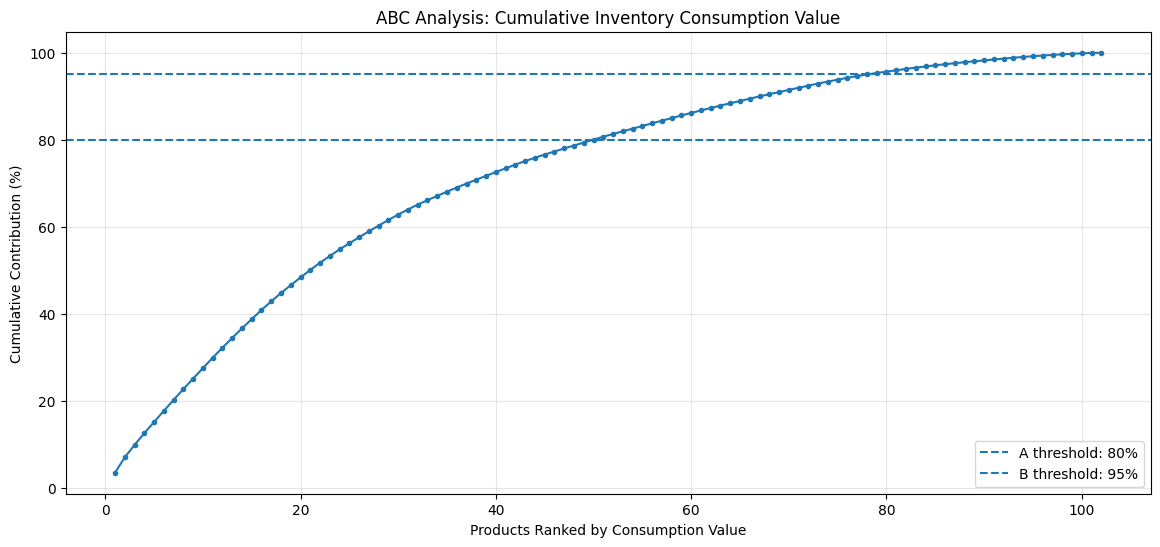

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    range(1, len(product_abc) + 1),
    product_abc['cumulative_pct'],
    marker='.'
)

plt.axhline(
    y=80,
    linestyle='--',
    label='A threshold: 80%'
)

plt.axhline(
    y=95,
    linestyle='--',
    label='B threshold: 95%'
)

plt.title('ABC Analysis: Cumulative Inventory Consumption Value')
plt.xlabel('Products Ranked by Consumption Value')
plt.ylabel('Cumulative Contribution (%)')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [49]:
# Find the first product rank reaching 80% and 95%
a_boundary = product_abc[
    product_abc['cumulative_pct'] >= 80
].index[0] + 1

b_boundary = product_abc[
    product_abc['cumulative_pct'] >= 95
].index[0] + 1

print("A boundary rank:", a_boundary)
print("B boundary rank:", b_boundary)

print("Products reaching 80%:", a_boundary)
print("Products reaching 95%:", b_boundary)

A boundary rank: 50
B boundary rank: 79
Products reaching 80%: 50
Products reaching 95%: 79


In [50]:
import numpy as np

product_abc['ABC_class'] = np.select(
    [
        product_abc['cumulative_pct'].shift(
            fill_value=0
        ) < 80,

        product_abc['cumulative_pct'].shift(
            fill_value=0
        ) < 95
    ],
    [
        'A',
        'B'
    ],
    default='C'
)

product_abc.head(20)

,sku_id,sku_name,category,total_units_sold,total_consumption_value,contribution_pct,cumulative_pct,ABC_class
0,SKU0027,BrandC Chips,Snacks,1200897,10202984.25,3.509346,3.509346,A
1,SKU0018,BrandF Water,Beverages,1173032,10201828.51,3.508948,7.018294,A
2,SKU0099,BrandC Toothpaste,Personal Care,1242389,8320295.30,2.861790,9.880084,A
3,SKU0026,BrandB Chips,Snacks,893989,7836533.94,2.695398,12.575482,A
4,SKU0092,BrandB Soap,Personal Care,895842,7497644.85,2.578837,15.154319,A
5,SKU0100,BrandD Toothpaste,Personal Care,920354,7413030.85,2.549733,17.704052,A
6,SKU0064,BrandD Cheese,Dairy,990120,7362677.09,2.532414,20.236466,A
7,SKU0061,BrandA Cheese,Dairy,972948,7167786.88,2.465381,22.701847,A
8,SKU0028,BrandD Chips,Snacks,1253907,7047743.56,2.424092,25.125939,A
9,SKU0041,BrandE Biscuits,Snacks,888200,6966794.21,2.396249,27.522188,A


In [51]:
abc_summary = product_abc.groupby(
    'ABC_class'
).agg(
    number_of_products=('sku_id', 'count'),
    total_consumption_value=(
        'total_consumption_value', 'sum'
    )
).reset_index()

abc_summary['product_percentage'] = (
    abc_summary['number_of_products']
    / len(product_abc)
) * 100

abc_summary['value_percentage'] = (
    abc_summary['total_consumption_value']
    / product_abc['total_consumption_value'].sum()
) * 100

abc_summary.round(2)

,ABC_class,number_of_products,total_consumption_value,product_percentage,value_percentage
0,A,50,2.327042e+08,49.02,80.04
1,B,29,4.448152e+07,28.43,15.30
2,C,23,1.355177e+07,22.55,4.66


XYZ tests

In [52]:
# Create a list of all months in the dataset
all_months = pd.date_range(
    start=df['date'].min().to_period('M').to_timestamp(),
    end=df['date'].max().to_period('M').to_timestamp(),
    freq='MS'
)

# Get all unique products
all_skus = df['sku_id'].unique()

# Create every possible SKU-month combination
full_index = pd.MultiIndex.from_product(
    [all_skus, all_months],
    names=['sku_id', 'date']
)

# Calculate monthly demand for each SKU
monthly_sku_demand = (
    df.groupby([
        pd.Grouper(key='date', freq='MS'),
        'sku_id'
    ])['units_sold']
    .sum()
    .rename('monthly_units')
    .reset_index()
)

# Fill missing SKU-month combinations with zero demand
monthly_sku_demand = (
    monthly_sku_demand
    .set_index(['sku_id', 'date'])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

# Inspect the results
monthly_sku_demand.head()

,sku_id,date,monthly_units
0,SKU0086,2021-01-01,3218
1,SKU0086,2021-02-01,2592
2,SKU0086,2021-03-01,2855
3,SKU0086,2021-04-01,2976
4,SKU0086,2021-05-01,3406


Demand variablity calculations

In [53]:
# Calculate average and standard deviation of monthly demand
xyz_analysis = monthly_sku_demand.groupby('sku_id').agg(
    mean_monthly_demand=('monthly_units', 'mean'),
    std_monthly_demand=('monthly_units', 'std')
).reset_index()

# Calculate coefficient of variation
xyz_analysis['CV'] = (
    xyz_analysis['std_monthly_demand'] /
    xyz_analysis['mean_monthly_demand']
)

# Round results for easier interpretation
xyz_analysis = xyz_analysis.round(3)

# Display first 10 products
xyz_analysis.head(10)

,sku_id,mean_monthly_demand,std_monthly_demand,CV
0,SKU0001,49788.361,9780.079,0.196
1,SKU0002,21297.750,4266.228,0.200
2,SKU0003,7010.444,1374.256,0.196
3,SKU0004,30526.333,6056.693,0.198
4,SKU0005,30458.333,6560.332,0.215
5,SKU0006,46171.528,9517.412,0.206
6,SKU0007,9430.917,1866.006,0.198
7,SKU0008,7708.944,1554.683,0.202
8,SKU0009,20525.222,4025.791,0.196
9,SKU0010,12581.472,2758.775,0.219


In [54]:
# Assign XYZ classes based on coefficient of variation
xyz_analysis['XYZ_class'] = np.select(
    [
        xyz_analysis['CV'] <= 0.5,
        xyz_analysis['CV'] <= 1.0
    ],
    ['X', 'Y'],
    default='Z'
)

# Count products in each class
xyz_summary = xyz_analysis.groupby('XYZ_class').agg(
    number_of_products=('sku_id', 'count'),
    average_CV=('CV', 'mean')
).reset_index()

# Calculate percentage of products in each class
xyz_summary['product_percentage'] = (
    xyz_summary['number_of_products'] /
    len(xyz_analysis) * 100
)

xyz_summary = xyz_summary.round(2)

xyz_summary

,XYZ_class,number_of_products,average_CV,product_percentage
0,X,102,0.11,100.0


In [55]:
# Inspect the distribution of CV values
xyz_analysis['CV'].describe()


,CV
count,102.000000
mean,0.107049
std,0.072525
min,0.029000
25%,0.037250
50%,0.076500
75%,0.197500
max,0.242000


In [56]:
# Count products within different CV ranges
print("Minimum CV:", xyz_analysis['CV'].min())
print("Maximum CV:", xyz_analysis['CV'].max())

print("Products with CV <= 0.5:",
      (xyz_analysis['CV'] <= 0.5).sum())

print("Products with CV > 0.5 and <= 1:",
      ((xyz_analysis['CV'] > 0.5) &
       (xyz_analysis['CV'] <= 1)).sum())

print("Products with CV > 1:",
      (xyz_analysis['CV'] > 1).sum())

Minimum CV: 0.029
Maximum CV: 0.242
Products with CV <= 0.5: 102
Products with CV > 0.5 and <= 1: 0
Products with CV > 1: 0


In [57]:
# Combine ABC and XYZ classifications
abc_xyz = product_abc.merge(
    xyz_analysis[['sku_id', 'mean_monthly_demand',
                  'std_monthly_demand', 'CV', 'XYZ_class']],
    on='sku_id',
    how='inner'
)

# Create combined classification
abc_xyz['ABC_XYZ_class'] = (
    abc_xyz['ABC_class'] + abc_xyz['XYZ_class']
)

# Display selected columns
abc_xyz[[
    'sku_id',
    'sku_name',
    'category',
    'ABC_class',
    'XYZ_class',
    'ABC_XYZ_class',
    'total_consumption_value',
    'mean_monthly_demand',
    'CV'
]].head(10)

,sku_id,sku_name,category,ABC_class,XYZ_class,ABC_XYZ_class,total_consumption_value,mean_monthly_demand,CV
0,SKU0027,BrandC Chips,Snacks,A,X,AX,10202984.25,33358.250,0.100
1,SKU0018,BrandF Water,Beverages,A,X,AX,10201828.51,32584.222,0.205
2,SKU0099,BrandC Toothpaste,Personal Care,A,X,AX,8320295.30,34510.806,0.078
3,SKU0026,BrandB Chips,Snacks,A,X,AX,7836533.94,24833.028,0.111
4,SKU0092,BrandB Soap,Personal Care,A,X,AX,7497644.85,24884.500,0.040
5,SKU0100,BrandD Toothpaste,Personal Care,A,X,AX,7413030.85,25565.389,0.031
6,SKU0064,BrandD Cheese,Dairy,A,X,AX,7362677.09,27503.333,0.034
7,SKU0061,BrandA Cheese,Dairy,A,X,AX,7167786.88,27026.333,0.031
8,SKU0028,BrandD Chips,Snacks,A,X,AX,7047743.56,34830.750,0.117
9,SKU0041,BrandE Biscuits,Snacks,A,X,AX,6966794.21,24672.222,0.139


In [58]:
# Count products and calculate consumption value
abc_xyz_summary = abc_xyz.groupby('ABC_XYZ_class').agg(
    number_of_products=('sku_id', 'count'),
    total_consumption_value=('total_consumption_value', 'sum')
).reset_index()

# Calculate percentage of products and value
abc_xyz_summary['product_percentage'] = (
    abc_xyz_summary['number_of_products'] /
    len(abc_xyz) * 100
)

abc_xyz_summary['value_percentage'] = (
    abc_xyz_summary['total_consumption_value'] /
    abc_xyz['total_consumption_value'].sum() * 100
)

abc_xyz_summary.round(2)

,ABC_XYZ_class,number_of_products,total_consumption_value,product_percentage,value_percentage
0,AX,50,2.327042e+08,49.02,80.04
1,BX,29,4.448152e+07,28.43,15.30
2,CX,23,1.355177e+07,22.55,4.66


HYPOTHESES TESTING

daily demand data

In [59]:
# Aggregate total units sold per day
daily_demand = (
    df.groupby('date')
    .agg(total_units_sold=('units_sold', 'sum'))
    .reset_index()
)

# Identify weekdays and weekends
daily_demand['day_type'] = np.where(
    daily_demand['date'].dt.dayofweek.isin([5, 6]),
    'Weekend',
    'Weekday'
)

# Check the results
daily_demand.head()

,date,total_units_sold,day_type
0,2021-01-01,53924,Weekday
1,2021-01-02,68546,Weekend
2,2021-01-03,68066,Weekend
3,2021-01-04,55802,Weekday
4,2021-01-05,53234,Weekday


calculating descriptive statistics

In [60]:
#descriptive statistics for each day type
demand_summary = daily_demand.groupby('day_type').agg(
    number_of_days=('total_units_sold', 'count'),
    average_daily_demand=('total_units_sold', 'mean'),
    median_daily_demand=('total_units_sold', 'median'),
    std_daily_demand=('total_units_sold', 'std'),
    minimum_demand=('total_units_sold', 'min'),
    maximum_demand=('total_units_sold', 'max')
).reset_index()

demand_summary.round(2)

,day_type,number_of_days,average_daily_demand,median_daily_demand,std_daily_demand,minimum_demand,maximum_demand
0,Weekday,781,56275.97,55361.0,3294.28,49555,66093
1,Weekend,314,67402.70,66504.5,3850.03,59690,77372


visualizing the comparison

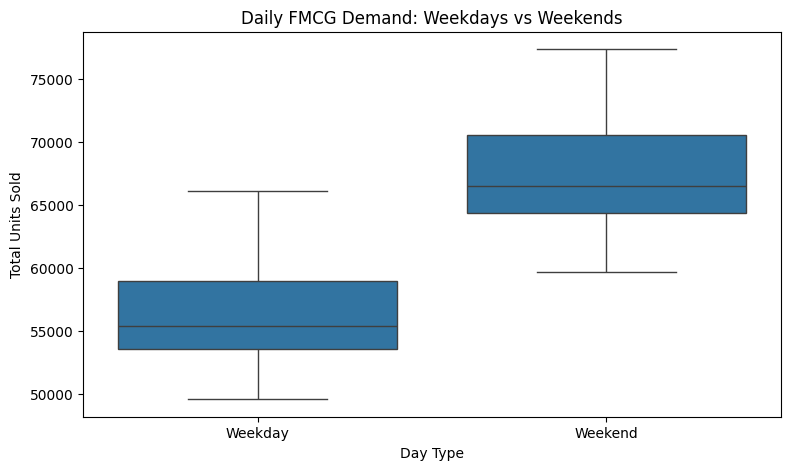

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=daily_demand,
    x='day_type',
    y='total_units_sold'
)

plt.title('Daily FMCG Demand: Weekdays vs Weekends')
plt.xlabel('Day Type')
plt.ylabel('Total Units Sold')
plt.show()

conducting statistical test using Welch's independent two-sample t-test

In [62]:
from scipy.stats import ttest_ind

# Separate weekday and weekend demand
weekday_demand = daily_demand.loc[
    daily_demand['day_type'] == 'Weekday',
    'total_units_sold'
]

weekend_demand = daily_demand.loc[
    daily_demand['day_type'] == 'Weekend',
    'total_units_sold'
]

# Perform Welch's t-test
t_statistic, p_value = ttest_ind(
    weekday_demand,
    weekend_demand,
    equal_var=False
)

print("T-statistic:", t_statistic)
print("P-value:", p_value)

T-statistic: -45.01339356131693
P-value: 3.36939536627803e-179


In [63]:
#hypothesis test findings
print("Reject the null hypothesis")

Reject the null hypothesis


In [64]:
from scipy.stats import ttest_rel

# Assign each date to the Monday of its calendar week
daily_demand['week_start'] = (
    daily_demand['date']
    - pd.to_timedelta(daily_demand['date'].dt.dayofweek, unit='D')
)

# Calculate average demand and number of days per group in each week
weekly_comparison = daily_demand.pivot_table(
    index='week_start',
    columns='day_type',
    values='total_units_sold',
    aggfunc=['mean', 'count']
)

# Keep only complete weeks: 5 weekdays and 2 weekend days
complete_weeks = weekly_comparison[
    (weekly_comparison[('count', 'Weekday')] == 5) &
    (weekly_comparison[('count', 'Weekend')] == 2)
]

# Compare weekday and weekend averages within each week
paired_test = ttest_rel(
    complete_weeks[('mean', 'Weekday')],
    complete_weeks[('mean', 'Weekend')]
)

print("Complete weeks:", len(complete_weeks))
print("Average weekday demand:",
      complete_weeks[('mean', 'Weekday')].mean())
print("Average weekend demand:",
      complete_weeks[('mean', 'Weekend')].mean())
print("Paired t-statistic:", paired_test.statistic)
print("Paired p-value:", paired_test.pvalue)

Complete weeks: 156
Average weekday demand: 56278.9858974359
Average weekend demand: 67396.91346153847
Paired t-statistic: -75.25560370323868
Paired p-value: 6.169596267807679e-124


### Hypothesis Testing: Weekday and Weekend Demand

A statistical investigation was conducted to determine whether average daily FMCG demand differs between weekdays and weekends.

The initial descriptive analysis showed that average weekday demand was 56,275.97 units, while average weekend demand was 67,402.70 units, representing approximately 19.77% higher demand during weekends.

An independent Welch's two-sample t-test produced a t-statistic of -45.0134 and a p-value of 3.3694 × 10⁻¹⁷⁹. Since the p-value was below the 0.05 significance level, the null hypothesis was rejected.

To strengthen the analysis, a paired t-test was conducted using 156 complete calendar weeks. The average weekday demand was 56,278.99 units, compared with 67,396.91 units during weekends. The paired test produced a t-statistic of -75.2556 and a p-value of 6.1696 × 10⁻¹²⁴.

Both tests provided strong statistical evidence of a difference in average daily demand, with weekend demand approximately 19.75% higher in the paired comparison.

The findings suggest that inventory planning should account for higher weekend demand. However, the analysis establishes an association rather than proving that the day of the week causes the demand difference.

FEATURE ENGINEERING

In [65]:
# copy of our monthly demand dataset
forecast_df = monthly_sku_demand.copy()

# product information
forecast_df = forecast_df.merge(
    product_info,
    on='sku_id',
    how='left'
)

# Sort by product and date
forecast_df = forecast_df.sort_values(
    ['sku_id', 'date']
).reset_index(drop=True)

# Creating calendar features
forecast_df['month'] = forecast_df['date'].dt.month
forecast_df['quarter'] = forecast_df['date'].dt.quarter

# Creating previous-month demand features
for lag in [1, 2, 3]:
    forecast_df[f'lag_{lag}'] = (
        forecast_df.groupby('sku_id')['monthly_units']
        .shift(lag)
    )

# Calculate the previous three-month average
forecast_df['rolling_mean_3'] = (
    forecast_df.groupby('sku_id')['monthly_units']
    .transform(
        lambda x: x.shift(1).rolling(
            window=3,
            min_periods=3
        ).mean()
    )
)

# Remove rows without sufficient historical information
forecast_df = forecast_df.dropna().reset_index(drop=True)

# Inspect the engineered dataset
forecast_df.head(10)

,sku_id,date,monthly_units,sku_name,category,month,quarter,lag_1,lag_2,lag_3,rolling_mean_3
0,SKU0001,2021-04-01,43922,BrandA Soda,Beverages,4,2,47504.0,42362.0,49190.0,46352.000000
1,SKU0001,2021-05-01,50141,BrandA Soda,Beverages,5,2,43922.0,47504.0,42362.0,44596.000000
2,SKU0001,2021-06-01,60077,BrandA Soda,Beverages,6,2,50141.0,43922.0,47504.0,47189.000000
3,SKU0001,2021-07-01,63525,BrandA Soda,Beverages,7,3,60077.0,50141.0,43922.0,51380.000000
4,SKU0001,2021-08-01,70848,BrandA Soda,Beverages,8,3,63525.0,60077.0,50141.0,57914.333333
5,SKU0001,2021-09-01,41533,BrandA Soda,Beverages,9,3,70848.0,63525.0,60077.0,64816.666667
6,SKU0001,2021-10-01,43840,BrandA Soda,Beverages,10,4,41533.0,70848.0,63525.0,58635.333333
7,SKU0001,2021-11-01,42530,BrandA Soda,Beverages,11,4,43840.0,41533.0,70848.0,52073.666667
8,SKU0001,2021-12-01,44061,BrandA Soda,Beverages,12,4,42530.0,43840.0,41533.0,42634.333333
9,SKU0001,2022-01-01,43893,BrandA Soda,Beverages,1,1,44061.0,42530.0,43840.0,43477.000000


In [66]:
# Start from the complete monthly demand dataset
forecast_df = monthly_sku_demand.copy()

# Add product information
forecast_df = forecast_df.merge(
    product_info,
    on='sku_id',
    how='left'
)

# Sort records chronologically for each SKU
forecast_df = forecast_df.sort_values(
    ['sku_id', 'date']
).reset_index(drop=True)

# Calendar features
forecast_df['month'] = forecast_df['date'].dt.month
forecast_df['quarter'] = forecast_df['date'].dt.quarter

# Historical demand features
for lag in [1, 2, 3, 12]:
    forecast_df[f'lag_{lag}'] = (
        forecast_df.groupby('sku_id')['monthly_units']
        .shift(lag)
    )

# Previous three-month average
forecast_df['rolling_mean_3'] = (
    forecast_df.groupby('sku_id')['monthly_units']
    .transform(
        lambda x: x.shift(1).rolling(
            window=3,
            min_periods=3
        ).mean()
    )
)

# Remove rows without sufficient historical information
forecast_df = forecast_df.dropna().reset_index(drop=True)

# Inspect the final features
forecast_df.head(10)

,sku_id,date,monthly_units,sku_name,category,month,quarter,lag_1,lag_2,lag_3,lag_12,rolling_mean_3
0,SKU0001,2022-01-01,43893,BrandA Soda,Beverages,1,1,44061.0,42530.0,43840.0,49190.0,43477.000000
1,SKU0001,2022-02-01,37504,BrandA Soda,Beverages,2,1,43893.0,44061.0,42530.0,42362.0,43494.666667
2,SKU0001,2022-03-01,45492,BrandA Soda,Beverages,3,1,37504.0,43893.0,44061.0,47504.0,41819.333333
3,SKU0001,2022-04-01,41297,BrandA Soda,Beverages,4,2,45492.0,37504.0,43893.0,43922.0,42296.333333
4,SKU0001,2022-05-01,42534,BrandA Soda,Beverages,5,2,41297.0,45492.0,37504.0,50141.0,41431.000000
5,SKU0001,2022-06-01,58877,BrandA Soda,Beverages,6,2,42534.0,41297.0,45492.0,60077.0,43107.666667
6,SKU0001,2022-07-01,69031,BrandA Soda,Beverages,7,3,58877.0,42534.0,41297.0,63525.0,47569.333333
7,SKU0001,2022-08-01,66581,BrandA Soda,Beverages,8,3,69031.0,58877.0,42534.0,70848.0,56814.000000
8,SKU0001,2022-09-01,43750,BrandA Soda,Beverages,9,3,66581.0,69031.0,58877.0,41533.0,64829.666667
9,SKU0001,2022-10-01,47002,BrandA Soda,Beverages,10,4,43750.0,66581.0,69031.0,43840.0,59787.333333


preparing the training and testing datasets

In [67]:
# Training data: 2022
train_df = forecast_df[
    forecast_df['date'].dt.year == 2022
].copy()

# Testing data: 2023
test_df = forecast_df[
    forecast_df['date'].dt.year == 2023
].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("Training period:",
      train_df['date'].min(),
      "to",
      train_df['date'].max())

print("Testing period:",
      test_df['date'].min(),
      "to",
      test_df['date'].max())

Training rows: 1224
Testing rows: 1224
Training period: 2022-01-01 00:00:00 to 2022-12-01 00:00:00
Testing period: 2023-01-01 00:00:00 to 2023-12-01 00:00:00


establishing baseline forecast

In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Seasonal naive predictions
baseline_predictions = test_df['lag_12']

# Calculate baseline evaluation metrics
baseline_mae = mean_absolute_error(
    test_df['monthly_units'],
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        test_df['monthly_units'],
        baseline_predictions
    )
)

baseline_wape = (
    np.abs(test_df['monthly_units'] - baseline_predictions).sum()
    / test_df['monthly_units'].sum()
) * 100

print("SEASONAL NAIVE BASELINE")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("WAPE:", round(baseline_wape, 2), "%")

SEASONAL NAIVE BASELINE
MAE: 796.37
RMSE: 1389.05
WAPE: 4.49 %


Training a Random Forest Model

In [69]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Select model features
features = [
    'sku_id',
    'category',
    'month',
    'quarter',
    'lag_1',
    'lag_2',
    'lag_3',
    'lag_12',
    'rolling_mean_3'
]

target = 'monthly_units'

# Separate training and testing features
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

# Identify categorical and numerical features
categorical_features = ['sku_id', 'category']

numerical_features = [
    'month',
    'quarter',
    'lag_1',
    'lag_2',
    'lag_3',
    'lag_12',
    'rolling_mean_3'
]

# Encode categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)

# Create the Random Forest pipeline
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest training completed.")

Random Forest training completed.


random forest evaluation

In [70]:
# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_wape = (
    np.abs(y_test - rf_predictions).sum()
    / y_test.sum()
) * 100

print("RANDOM FOREST RESULTS")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("WAPE:", round(rf_wape, 2), "%")

RANDOM FOREST RESULTS
MAE: 775.87
RMSE: 1352.76
WAPE: 4.38 %


model comparison

In [71]:
model_comparison = pd.DataFrame({
    'Model': ['Seasonal Naive', 'Random Forest'],
    'MAE': [baseline_mae, rf_mae],
    'RMSE': [baseline_rmse, rf_rmse],
    'WAPE (%)': [baseline_wape, rf_wape]
})

model_comparison.round(2)

,Model,MAE,RMSE,WAPE (%)
0,Seasonal Naive,796.37,1389.05,4.49
1,Random Forest,775.87,1352.76,4.38


In [72]:
# Create a DataFrame containing actual and predicted demand
forecast_results = test_df[['date', 'sku_id', 'monthly_units']].copy()

forecast_results['predicted_units'] = rf_predictions

# Aggregate demand across all products for each month
monthly_forecast = forecast_results.groupby('date').agg(
    actual_demand=('monthly_units', 'sum'),
    predicted_demand=('predicted_units', 'sum')
).reset_index()

monthly_forecast.head()

,date,actual_demand,predicted_demand
0,2023-01-01,1788545,1.822569e+06
1,2023-02-01,1628565,1.648740e+06
2,2023-03-01,1744216,1.734871e+06
3,2023-04-01,1707277,1.711328e+06
4,2023-05-01,1731937,1.751664e+06


Actual vs predicted amount visualization

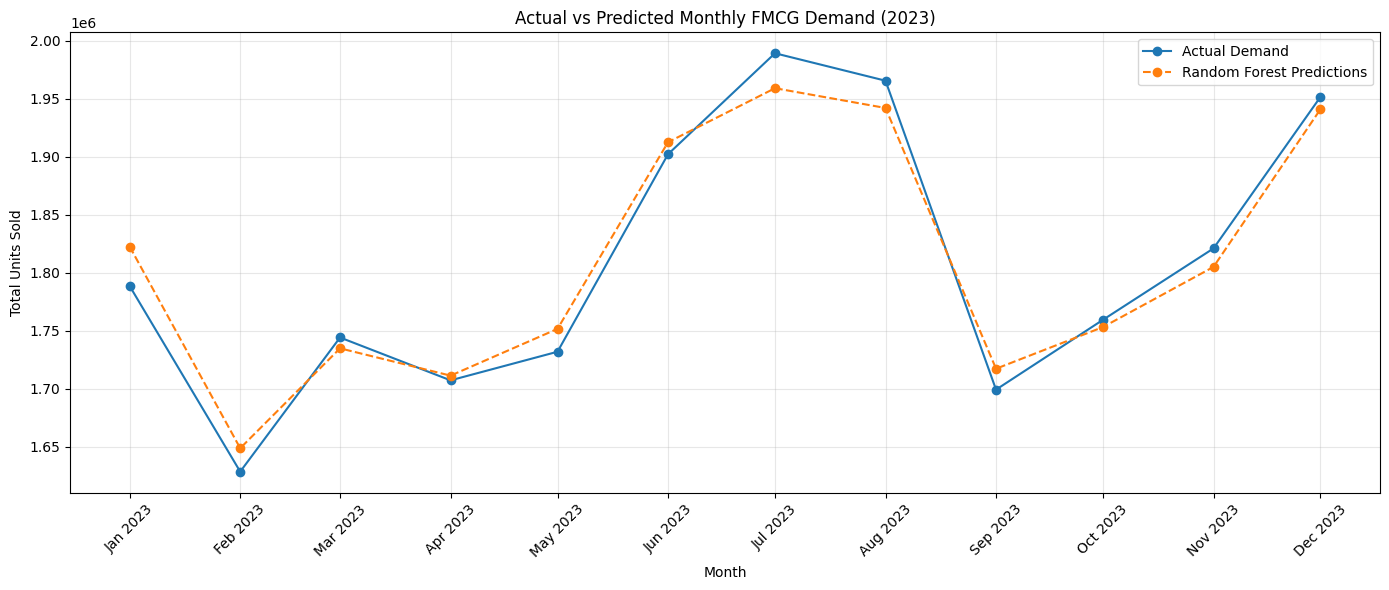

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_forecast['date'],
    monthly_forecast['actual_demand'],
    marker='o',
    label='Actual Demand'
)

plt.plot(
    monthly_forecast['date'],
    monthly_forecast['predicted_demand'],
    marker='o',
    linestyle='--',
    label='Random Forest Predictions'
)

plt.title('Actual vs Predicted Monthly FMCG Demand (2023)')
plt.xlabel('Month')
plt.ylabel('Total Units Sold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(monthly_forecast['date'], monthly_forecast['date'].dt.strftime('%b %Y'), rotation=45)

plt.tight_layout()
plt.show()

In [74]:
# Get the fitted preprocessing component
preprocessor = rf_model.named_steps['preprocessor']

# Get feature names after one-hot encoding
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importance_values = rf_model.named_steps['model'].feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': importance_values
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by='importance',
    ascending=False
).reset_index(drop=True)

feature_importance.head(15).round(4)

,feature,importance
0,remainder__lag_12,0.9879
1,remainder__lag_1,0.0030
2,remainder__rolling_mean_3,0.0027
3,remainder__lag_3,0.0017
4,remainder__lag_2,0.0017
5,remainder__month,0.0008
6,categorical__category_Snacks,0.0003
7,remainder__quarter,0.0002
8,categorical__category_Beverages,0.0002
9,categorical__sku_id_SKU0006,0.0002


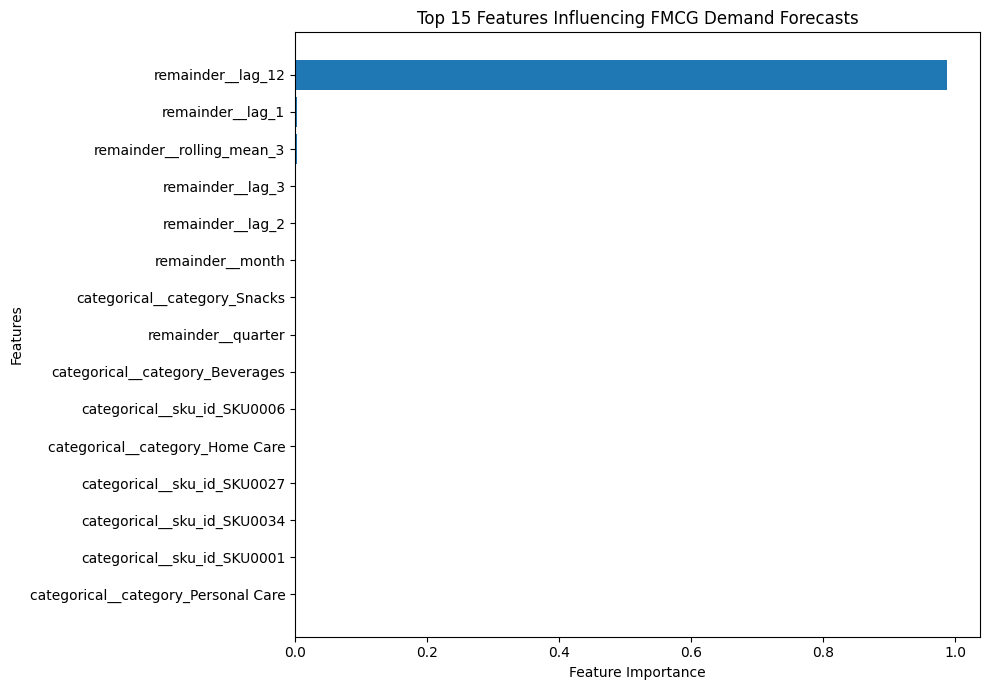

In [75]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by='importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['feature'],
    top_features['importance']
)

plt.title('Top 15 Features Influencing FMCG Demand Forecasts')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [76]:
monthly_forecast.round(2)

,date,actual_demand,predicted_demand
0,2023-01-01,1788545,1822568.95
1,2023-02-01,1628565,1648740.42
2,2023-03-01,1744216,1734870.72
3,2023-04-01,1707277,1711328.43
4,2023-05-01,1731937,1751663.61
5,2023-06-01,1902228,1912579.87
6,2023-07-01,1989263,1959123.51
7,2023-08-01,1965591,1942087.43
8,2023-09-01,1699259,1717291.76
9,2023-10-01,1759471,1753214.34
